In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import sys

print("Python version:", sys.version)
print("Python is working successfully!")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Python is working successfully!


In [3]:
!pip install pandas numpy matplotlib seaborn scikit-learn nltk

In [4]:
import zipfile
import os

zip_path = "/content/sms+spam+collection (2).zip"

extract_path = "/content/sms_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [5]:
import os

for root, folders, files in os.walk("/content/sms_dataset"):
    for file in files:
        print(file)

readme
SMSSpamCollection


In [6]:
import os

for root, folders, files in os.walk("/content/sms_dataset"):
    for file in files:
        print(os.path.join(root, file))

/content/sms_dataset/readme
/content/sms_dataset/SMSSpamCollection


In [7]:
import pandas as pd

file_path = "/content/sms_dataset/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [8]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

Dataset shape: (5572, 2)

Column names:
Index(['label', 'message'], dtype='object')

Missing values:
label      0
message    0
dtype: int64

Label distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [9]:
print("First 10 messages:")
display(df.head(10))

print("\nDataset information:")
df.info()

print("\nDataset statistics:")
print(df.describe(include="all"))

First 10 messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Dataset statistics:
       label                 message
count   5572                    5572
unique     2                    5169
top      ham  Sorry, I'll call later
freq    4825                      30


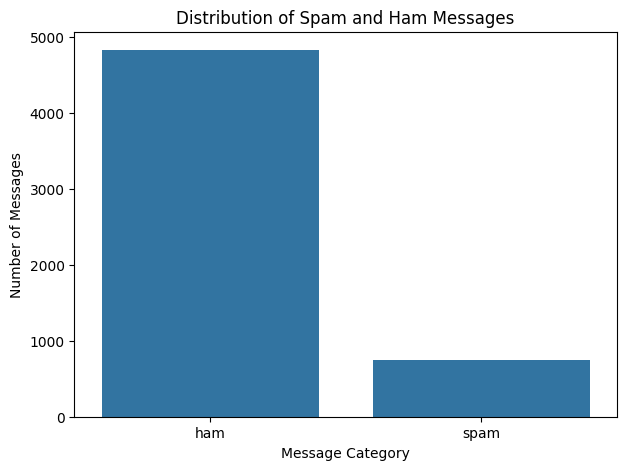

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

label_counts = df["label"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(x=label_counts.index, y=label_counts.values)

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [11]:
df["message_length"] = df["message"].apply(len)

print(df[["label", "message", "message_length"]].head(10))

  label                                            message  message_length
0   ham  Go until jurong point, crazy.. Available only ...             111
1   ham                      Ok lar... Joking wif u oni...              29
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...             155
3   ham  U dun say so early hor... U c already then say...              49
4   ham  Nah I don't think he goes to usf, he lives aro...              61
5  spam  FreeMsg Hey there darling it's been 3 week's n...             147
6   ham  Even my brother is not like to speak with me. ...              77
7   ham  As per your request 'Melle Melle (Oru Minnamin...             160
8  spam  WINNER!! As a valued network customer you have...             157
9  spam  Had your mobile 11 months or more? U R entitle...             154


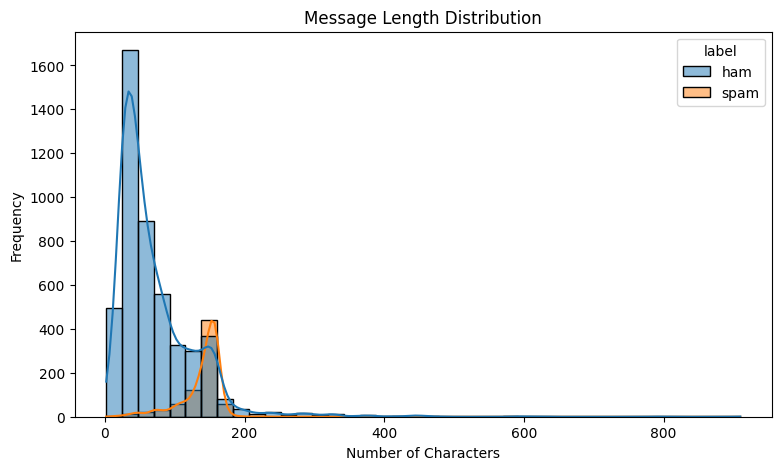

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=40,
    kde=True
)

plt.title("Message Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.show()

In [13]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate messages
print("\nDuplicate messages:")
print(df.duplicated().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
label             0
message           0
message_length    0
dtype: int64

Duplicate messages:
403

Duplicate rows:
403


In [14]:
# Remove duplicate rows
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("Dataset after removing duplicates:", df.shape)

Dataset after removing duplicates: (5169, 3)


In [15]:
import re
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [16]:
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print(df[["label", "label_num"]].head(10))

  label  label_num
0   ham          0
1   ham          0
2  spam          1
3   ham          0
4   ham          0
5  spam          1
6   ham          0
7   ham          0
8  spam          1
9  spam          1


In [17]:
def clean_text(text):

    text = text.lower()

    text = re.sub(r"http\S+|www\S+", "", text)

    text = re.sub(r"[^a-zA-Z\s]", "", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["clean_message"] = df["message"].apply(clean_text)

print(df[["message", "clean_message"]].head(10))

                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   
5  FreeMsg Hey there darling it's been 3 week's n...   
6  Even my brother is not like to speak with me. ...   
7  As per your request 'Melle Melle (Oru Minnamin...   
8  WINNER!! As a valued network customer you have...   
9  Had your mobile 11 months or more? U R entitle...   

                                       clean_message  
0  go until jurong point crazy available only in ...  
1                            ok lar joking wif u oni  
2  free entry in a wkly comp to win fa cup final ...  
3        u dun say so early hor u c already then say  
4  nah i dont think he goes to usf he lives aroun...  
5  freemsg hey there darling its been weeks now a... 

In [18]:
X = df["clean_message"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4135, 5000)
Testing data shape: (1034, 5000)


In [20]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [21]:
y_pred_nb = nb_model.predict(X_test_tfidf)

print("Actual labels:")
print(y_test[:10].tolist())

print("\nPredicted labels:")
print(y_pred_nb[:10].tolist())

Actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Predicted labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_nb))

print("Precision:", precision_score(y_test, y_pred_nb))

print("Recall:", recall_score(y_test, y_pred_nb))

print("F1 Score:", f1_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=["Ham", "Spam"]
))

Accuracy: 0.965183752417795
Precision: 1.0
Recall: 0.7251908396946565
F1 Score: 0.8407079646017699

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.73      0.84       131

    accuracy                           0.97      1034
   macro avg       0.98      0.86      0.91      1034
weighted avg       0.97      0.97      0.96      1034



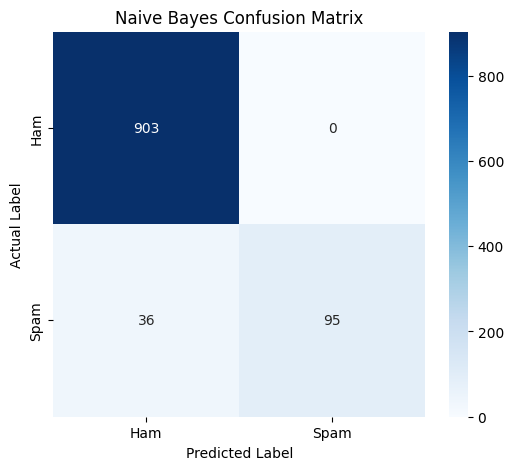

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [24]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [25]:
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Actual labels:")
print(y_test[:10].tolist())

print("\nPredicted labels:")
print(y_pred_lr[:10].tolist())

Actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Predicted labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [26]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

print("Logistic Regression Results")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Ham", "Spam"]
))

Logistic Regression Results
Accuracy: 0.9622823984526112
Precision: 0.9693877551020408
Recall: 0.7251908396946565
F1 Score: 0.8296943231441049

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       0.97      0.73      0.83       131

    accuracy                           0.96      1034
   macro avg       0.97      0.86      0.90      1034
weighted avg       0.96      0.96      0.96      1034



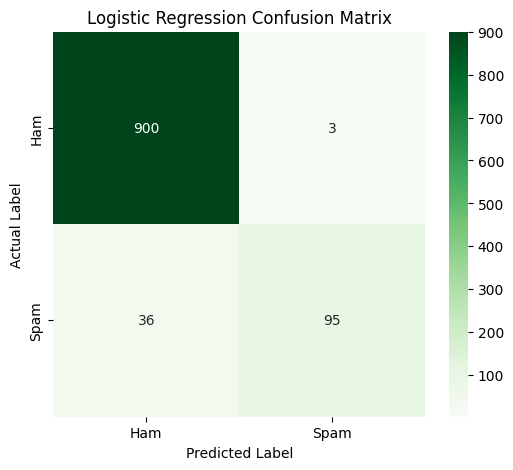

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [28]:
results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr)
    ],
    "Precision": [
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_lr)
    ],
    "Recall": [
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_lr)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_lr)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.9652,1.0000,0.7252,0.8407
1,Logistic Regression,0.9623,0.9694,0.7252,0.8297


In [29]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [30]:
y_pred_rf = rf_model.predict(X_test_tfidf)

print("Actual labels:")
print(y_test[:10].tolist())

print("\nPredicted labels:")
print(y_pred_rf[:10].tolist())

Actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Predicted labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Ham", "Spam"]
))

Random Forest Results
Accuracy: 0.9709864603481625
Precision: 1.0
Recall: 0.7709923664122137
F1 Score: 0.8706896551724138

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       1.00      0.77      0.87       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034



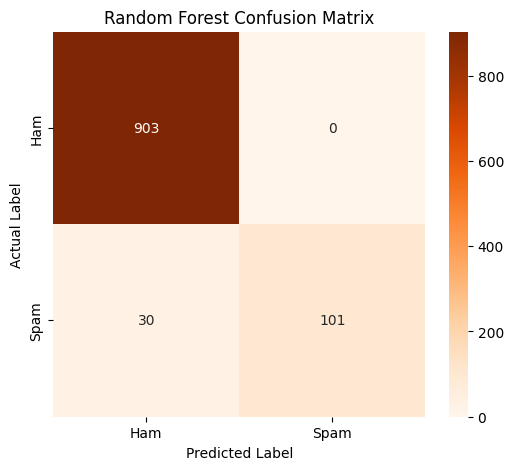

In [32]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [33]:
results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.9652,1.0000,0.7252,0.8407
1,Logistic Regression,0.9623,0.9694,0.7252,0.8297
2,Random Forest,0.9710,1.0000,0.7710,0.8707


In [34]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [35]:
import numpy as np

# Set vocabulary size
vocab_size = 10000

# Set maximum message length
max_length = 100

# Create tokenizer
tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

# Learn vocabulary from training messages only
tokenizer.fit_on_texts(X_train)

# Convert training messages into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)

# Convert testing messages into sequences
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Make all sequences equal in length
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

y_train_array = np.asarray(y_train)
y_test_array = np.asarray(y_test)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (4135, 100)
Testing shape: (1034, 100)


In [36]:
lstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        input_length=max_length
    ),

    LSTM(64),

    Dropout(0.5),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [38]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(
    X_train_pad,
    y_train_array,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.8715 - loss: 0.3907 - val_accuracy: 0.8937 - val_loss: 0.3500
Epoch 2/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.8715 - loss: 0.3927 - val_accuracy: 0.8937 - val_loss: 0.3446
Epoch 3/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.8715 - loss: 0.3884 - val_accuracy: 0.8937 - val_loss: 0.3387
Epoch 4/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - accuracy: 0.8715 - loss: 0.3895 - val_accuracy: 0.8937 - val_loss: 0.3452
Epoch 5/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.8715 - loss: 0.3897 - val_accuracy: 0.8937 - val_loss: 0.3399


In [39]:
y_prob_lstm = lstm_model.predict(X_test_pad)

y_pred_lstm = (y_prob_lstm >= 0.5).astype(int).ravel()

print("LSTM training completed!")

33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step
LSTM training completed!


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("LSTM Results")

print("Accuracy:", accuracy_score(y_test_array, y_pred_lstm))
print("Precision:", precision_score(y_test_array, y_pred_lstm))
print("Recall:", recall_score(y_test_array, y_pred_lstm))
print("F1 Score:", f1_score(y_test_array, y_pred_lstm))

print("\nClassification Report:")

print(classification_report(
    y_test_array,
    y_pred_lstm,
    target_names=["Ham", "Spam"]
))

LSTM Results
Accuracy: 0.8733075435203095
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Classification Report:
              precision    recall  f1-score   support

         Ham       0.87      1.00      0.93       903
        Spam       0.00      0.00      0.00       131

    accuracy                           0.87      1034
   macro avg       0.44      0.50      0.47      1034
weighted avg       0.76      0.87      0.81      1034



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

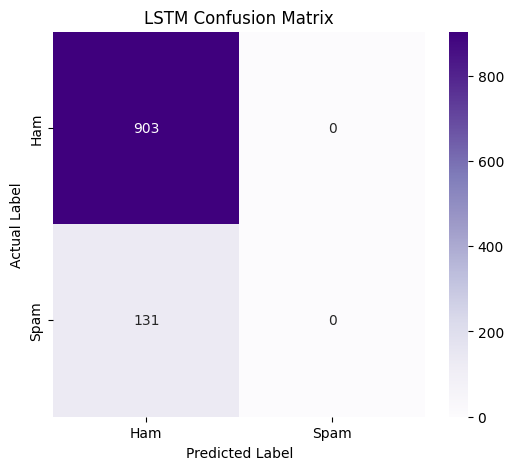

In [41]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_lstm = confusion_matrix(y_test_array, y_pred_lstm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

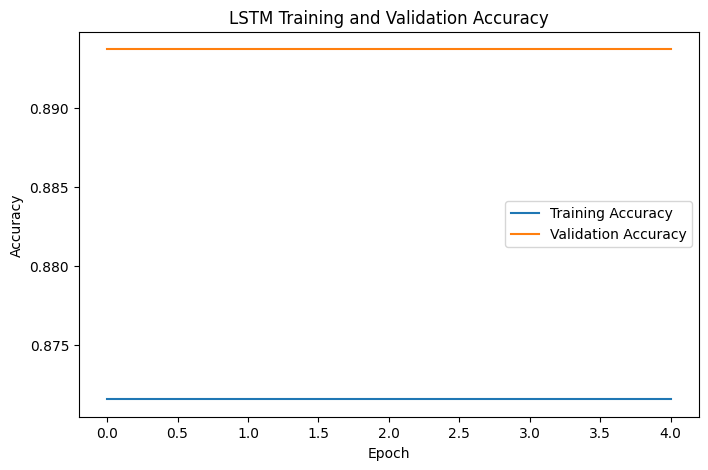

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(history_lstm.history["accuracy"], label="Training Accuracy")
plt.plot(history_lstm.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

In [43]:
from tensorflow.keras.layers import Bidirectional

print("BiLSTM library imported successfully!")

BiLSTM library imported successfully!


In [44]:
bilstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128
    ),

    Bidirectional(LSTM(64)),

    Dropout(0.5),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

bilstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

bilstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [45]:
early_stop_bilstm = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_bilstm = bilstm_model.fit(
    X_train_pad,
    y_train_array,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop_bilstm],
    verbose=1
)

Epoch 1/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 15s 96ms/step - accuracy: 0.9264 - loss: 0.2161 - val_accuracy: 0.9903 - val_loss: 0.0481
Epoch 2/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 11s 93ms/step - accuracy: 0.9866 - loss: 0.0494 - val_accuracy: 0.9879 - val_loss: 0.0449
Epoch 3/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 20s 86ms/step - accuracy: 0.9949 - loss: 0.0222 - val_accuracy: 0.9903 - val_loss: 0.0541
Epoch 4/10
117/117 ━━━━━━━━━━━━━━━━━━━━ 10s 87ms/step - accuracy: 0.9973 - loss: 0.0094 - val_accuracy: 0.9831 - val_loss: 0.0815


In [46]:
y_prob_bilstm = bilstm_model.predict(X_test_pad)

y_pred_bilstm = (y_prob_bilstm >= 0.5).astype(int).ravel()

print("BiLSTM predictions completed!")

33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step
BiLSTM predictions completed!


In [47]:
print("BiLSTM Results")

print("Accuracy:", accuracy_score(y_test_array, y_pred_bilstm))

print("Precision:", precision_score(y_test_array, y_pred_bilstm))

print("Recall:", recall_score(y_test_array, y_pred_bilstm))

print("F1 Score:", f1_score(y_test_array, y_pred_bilstm))

print("\nClassification Report:")

print(classification_report(
    y_test_array,
    y_pred_bilstm,
    target_names=["Ham", "Spam"]
))

BiLSTM Results
Accuracy: 0.9816247582205029
Precision: 0.9590163934426229
Recall: 0.8931297709923665
F1 Score: 0.924901185770751

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       903
        Spam       0.96      0.89      0.92       131

    accuracy                           0.98      1034
   macro avg       0.97      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



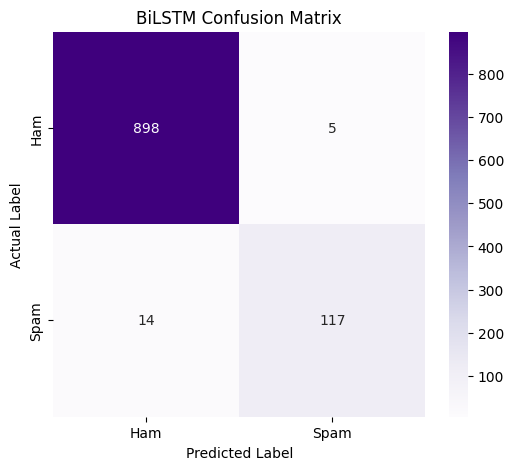

In [48]:
cm_bilstm = confusion_matrix(
    y_test_array,
    y_pred_bilstm
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_bilstm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("BiLSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

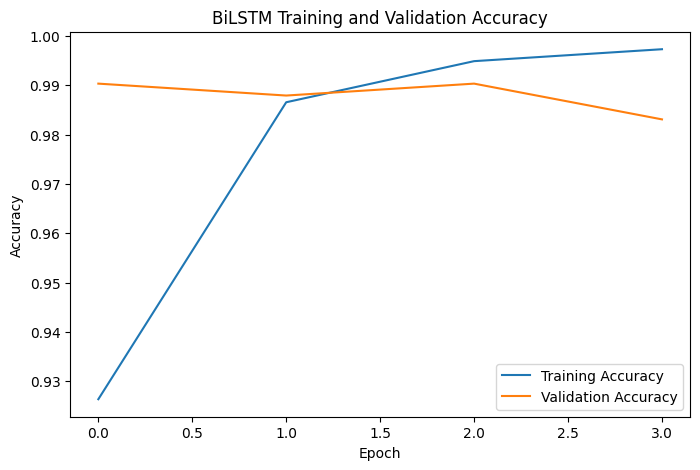

In [49]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_bilstm.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_bilstm.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("BiLSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

In [50]:
deep_learning_results = pd.DataFrame({
    "Model": ["LSTM", "BiLSTM"],
    "Accuracy": [
        accuracy_score(y_test_array, y_pred_lstm),
        accuracy_score(y_test_array, y_pred_bilstm)
    ],
    "Precision": [
        precision_score(y_test_array, y_pred_lstm),
        precision_score(y_test_array, y_pred_bilstm)
    ],
    "Recall": [
        recall_score(y_test_array, y_pred_lstm),
        recall_score(y_test_array, y_pred_bilstm)
    ],
    "F1 Score": [
        f1_score(y_test_array, y_pred_lstm),
        f1_score(y_test_array, y_pred_bilstm)
    ]
})

display(deep_learning_results.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Model,Accuracy,Precision,Recall,F1 Score
0,LSTM,0.8733,0.000,0.0000,0.0000
1,BiLSTM,0.9816,0.959,0.8931,0.9249


In [51]:
!pip install -q transformers datasets accelerate evaluate

In [52]:
import torch
import numpy as np

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

from datasets import Dataset
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")
print("GPU available:", torch.cuda.is_available())

Libraries imported successfully!
GPU available: False


In [53]:
model_name = "distilbert-base-uncased"

tokenizer_bert = AutoTokenizer.from_pretrained(model_name)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

print("DistilBERT loaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT loaded successfully!


In [54]:
train_df = pd.DataFrame({
    "text": X_train.tolist(),
    "labels": y_train.tolist()
})

test_df = pd.DataFrame({
    "text": X_test.tolist(),
    "labels": y_test.tolist()
})

train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 4135
Testing samples: 1034


In [55]:
def tokenize_messages(batch):
    return tokenizer_bert(
        batch["text"],
        truncation=True,
        max_length=128
    )

train_dataset = train_dataset.map(
    tokenize_messages,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_messages,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer_bert
)

print("Tokenization completed!")

Map:   0%|          | 0/4135 [00:00<?, ? examples/s]

Map:   0%|          | 0/1034 [00:00<?, ? examples/s]

Tokenization completed!


In [56]:
def compute_metrics(eval_pred):

    predictions, labels = eval_pred

    predictions = np.argmax(predictions, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [57]:
training_args = TrainingArguments(
    output_dir="/content/distilbert_results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    report_to="none"
)

In [58]:
trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    processing_class=tokenizer_bert,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.059106,0.978723,0.903704,0.931298,0.917293
2,0.076635,0.047194,0.988395,0.983740,0.923664,0.952756
3,0.076635,0.054420,0.988395,0.991736,0.916031,0.952381


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=777, training_loss=0.0577866776416047, metrics={'train_runtime': 2655.9406, 'train_samples_per_second': 4.671, 'train_steps_per_second': 0.293, 'total_flos': 147734783801880.0, 'train_loss': 0.0577866776416047, 'epoch': 3.0})

In [59]:
bert_results = trainer.evaluate()

print("DistilBERT Evaluation:")
print(bert_results)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.076635,0.047194,3,0.988395,0.983740,0.923664,0.952756


DistilBERT Evaluation:
{'eval_loss': 0.04719419777393341, 'eval_accuracy': 0.988394584139265, 'eval_precision': 0.983739837398374, 'eval_recall': 0.9236641221374046, 'eval_f1': 0.952755905511811}


In [60]:
bert_predictions = trainer.predict(test_dataset)

y_pred_bert = np.argmax(
    bert_predictions.predictions,
    axis=1
)

print(classification_report(
    y_test,
    y_pred_bert,
    target_names=["Ham", "Spam"]
))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       0.98      0.92      0.95       131

    accuracy                           0.99      1034
   macro avg       0.99      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



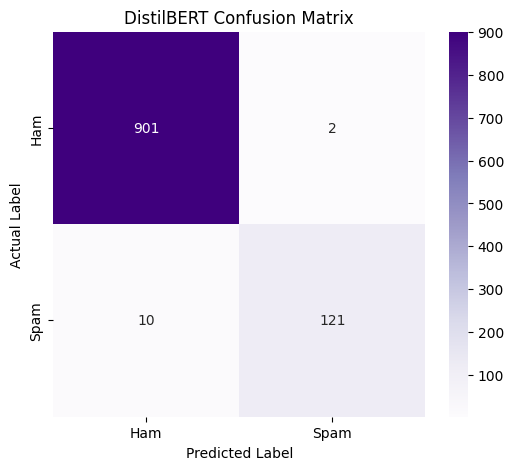

In [61]:
cm_bert = confusion_matrix(y_test, y_pred_bert)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_bert,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

results = []

# Naive Bayes
results.append({
    "Model": "Naive Bayes",
    "Accuracy": accuracy_score(y_test, y_pred_nb),
    "Precision": precision_score(y_test, y_pred_nb, zero_division=0),
    "Recall": recall_score(y_test, y_pred_nb, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_nb, zero_division=0)
})

# Logistic Regression
results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Precision": precision_score(y_test, y_pred_lr, zero_division=0),
    "Recall": recall_score(y_test, y_pred_lr, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_lr, zero_division=0)
})

# Random Forest
results.append({
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf, zero_division=0),
    "Recall": recall_score(y_test, y_pred_rf, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_rf, zero_division=0)
})

# LSTM
results.append({
    "Model": "LSTM",
    "Accuracy": accuracy_score(y_test_array, y_pred_lstm),
    "Precision": precision_score(y_test_array, y_pred_lstm, zero_division=0),
    "Recall": recall_score(y_test_array, y_pred_lstm, zero_division=0),
    "F1 Score": f1_score(y_test_array, y_pred_lstm, zero_division=0)
})

# BiLSTM
results.append({
    "Model": "BiLSTM",
    "Accuracy": accuracy_score(y_test_array, y_pred_bilstm),
    "Precision": precision_score(y_test_array, y_pred_bilstm, zero_division=0),
    "Recall": recall_score(y_test_array, y_pred_bilstm, zero_division=0),
    "F1 Score": f1_score(y_test_array, y_pred_bilstm, zero_division=0)
})

# DistilBERT
results.append({
    "Model": "DistilBERT",
    "Accuracy": accuracy_score(y_test, y_pred_bert),
    "Precision": precision_score(y_test, y_pred_bert, zero_division=0),
    "Recall": recall_score(y_test, y_pred_bert, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_bert, zero_division=0)
})

comparison_df = pd.DataFrame(results)

print("FINAL MODEL COMPARISON")
display(comparison_df.round(4))

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.9652,1.0000,0.7252,0.8407
1,Logistic Regression,0.9623,0.9694,0.7252,0.8297
2,Random Forest,0.9710,1.0000,0.7710,0.8707
3,LSTM,0.8733,0.0000,0.0000,0.0000
4,BiLSTM,0.9816,0.9590,0.8931,0.9249
5,DistilBERT,0.9884,0.9837,0.9237,0.9528


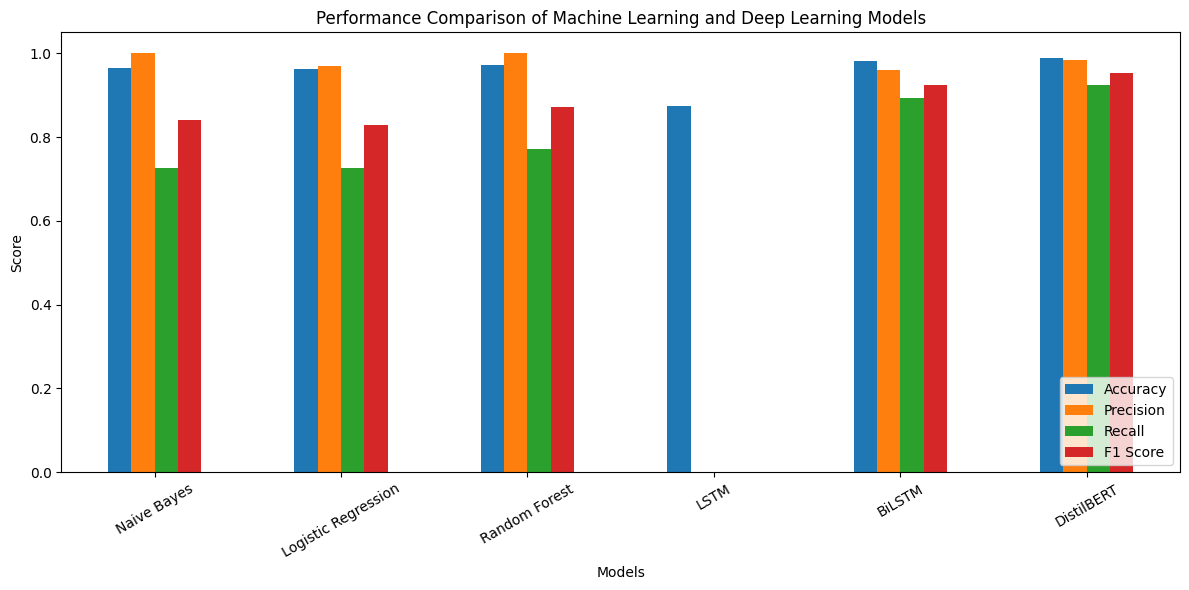

In [63]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Machine Learning and Deep Learning Models")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

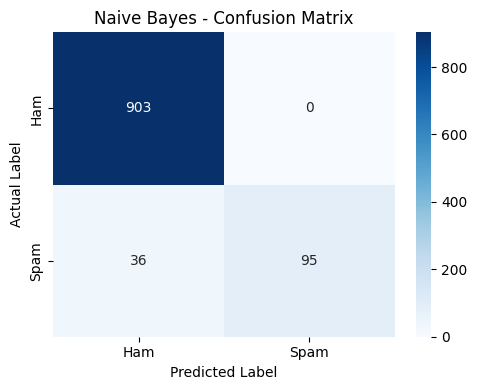

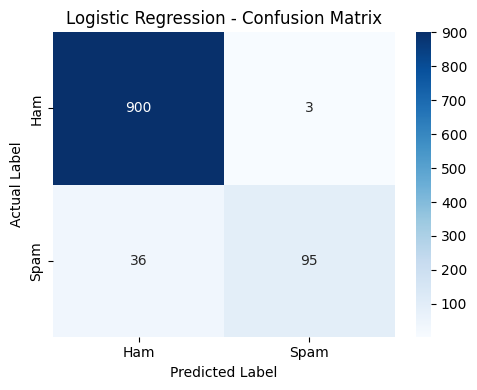

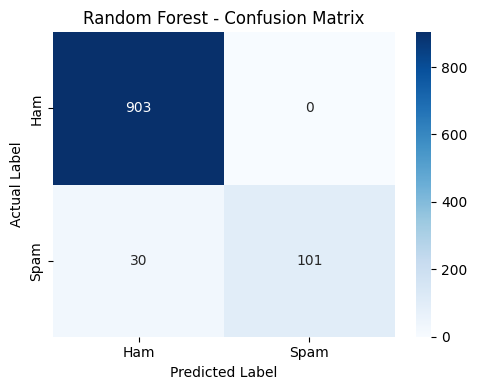

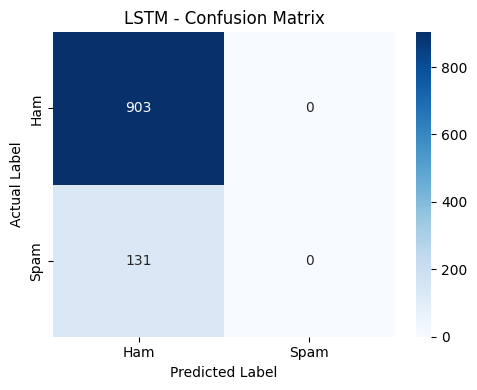

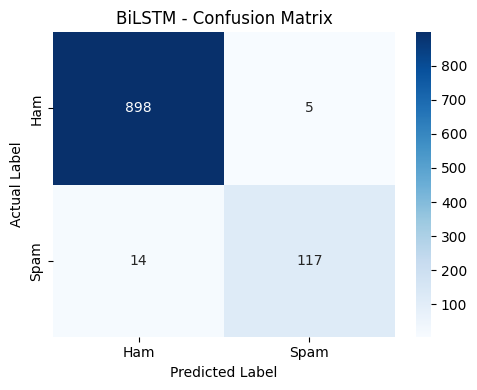

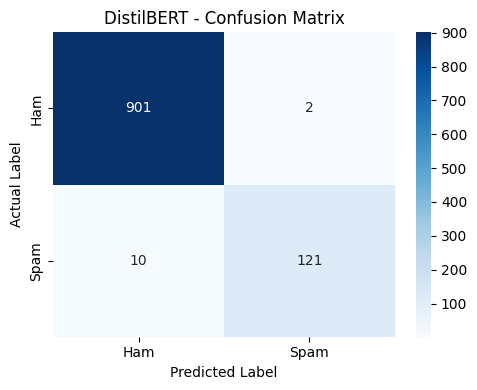

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models = {
    "Naive Bayes": (y_test, y_pred_nb),
    "Logistic Regression": (y_test, y_pred_lr),
    "Random Forest": (y_test, y_pred_rf),
    "LSTM": (y_test_array, y_pred_lstm),
    "BiLSTM": (y_test_array, y_pred_bilstm),
    "DistilBERT": (y_test, y_pred_bert)
}

for model_name, (actual, predicted) in models.items():

    cm = confusion_matrix(actual, predicted)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    plt.title(model_name + " - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

In [65]:
comparison_df.to_csv(
    "/content/model_comparison_results.csv",
    index=False
)

print("Comparison results saved successfully!")

Comparison results saved successfully!


In [66]:
from google.colab import files

files.download("/content/model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
import joblib
import os

os.makedirs("/content/saved_models", exist_ok=True)

# Save machine learning models
joblib.dump(nb_model, "/content/saved_models/naive_bayes.pkl")
joblib.dump(lr_model, "/content/saved_models/logistic_regression.pkl")
joblib.dump(rf_model, "/content/saved_models/random_forest.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, "/content/saved_models/tfidf_vectorizer.pkl")

print("Traditional ML models saved successfully!")

Traditional ML models saved successfully!


In [68]:
lstm_model.save("/content/saved_models/lstm_model.keras")

bilstm_model.save("/content/saved_models/bilstm_model.keras")

print("LSTM and BiLSTM models saved successfully!")

LSTM and BiLSTM models saved successfully!


In [69]:
bert_model.save_pretrained("/content/saved_models/distilbert_model")
tokenizer_bert.save_pretrained("/content/saved_models/distilbert_model")

print("DistilBERT model and tokenizer saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model and tokenizer saved successfully!


In [70]:
import pickle

with open("/content/saved_models/text_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

print("Text tokenizer saved successfully!")

Text tokenizer saved successfully!


In [71]:
import shutil

shutil.make_archive(
    "/content/AI_Scam_Detection_Models",
    "zip",
    "/content/saved_models"
)

from google.colab import files

files.download("/content/AI_Scam_Detection_Models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>